In [33]:
#####     Supplementary Figures (2)     #####
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
from joblib import load

import cartopy.crs as ccrs
import matplotlib.pyplot as plt

ROOT = Path.cwd()
DATA_DIR = ROOT / "Data"

lat_edges = np.arange(-90, 91, 1)
lon_edges = np.arange(0, 361, 1)
lat_centers = lat_edges[:-1] + 0.5
lon_centers = lon_edges[:-1] + 0.5\

def flipImage(tiff:np.ndarray):
    """Flip latitude and shift longitude from 0-360 to -180-180 style layout."""
    tiff = np.flip(tiff, axis=0)
    temp = np.zeros_like(tiff)
    temp[:, :180] = tiff[:, 180:]
    temp[:, 180:] = tiff[:, :180]
    tiff = temp
    return tiff

**Plot Observations Validation**


In [34]:
plots = pd.read_csv(DATA_DIR / "plots-agc.csv")
plots = plots.loc[:, ~plots.columns.str.startswith("Unnamed")].copy()

cci_file = np.load(DATA_DIR / "AGBC_ESAv7.npz")
cci_se_file = np.load(DATA_DIR / "AGBCsd_ESAv7.npz")
cci_agc = flipImage(cci_file["mean"].astype(float))
cci_se = flipImage(cci_se_file["mean"].astype(float))

cmip_file = np.load(DATA_DIR / "CMIP6_AGBC.npz")
model_names = cmip_file.files
cmip_models = np.stack([
    cmip_file[name].astype(float)
    for name in model_names
])
with warnings.catch_warnings(action="ignore"):
    cmip_mme = np.nanmean(cmip_models, axis=0)
    cmip_sd = np.nanstd(cmip_models, axis=0, ddof=0)

lat_idx = np.rint(plots["grid_lat"] - lat_centers[0]).astype(int)
plot_lon_0360 = np.mod(plots["grid_lon"], 360)
lon_idx = np.rint(plot_lon_0360 - lon_centers[0]).astype(int)
assert np.allclose(lat_centers[lat_idx], plots["grid_lat"])
assert np.allclose(lon_centers[lon_idx], plot_lon_0360)

# apply tree mask
treemask = load(DATA_DIR / "Masks/treemask.joblib").astype(float)
treemask[treemask==0] = np.nan
cci_agc = cci_agc * treemask
cmip_mme = cmip_mme * treemask

matched = plots.copy()
print(f"Total plot samples: {len(plots)}")
matched["cci_agc"] = cci_agc[lat_idx, lon_idx]
matched["cci_se"] = cci_se[lat_idx, lon_idx]
matched["cmip_mme"] = cmip_mme[lat_idx, lon_idx]
matched["cmip_sd"] = cmip_sd[lat_idx, lon_idx]
matched["cmip_n"] = np.isfinite(cmip_models[:, lat_idx, lon_idx]).sum(axis=0)

# --- Tree Fraction Correction --- #
TreeFrac = load(DATA_DIR / "Masks/treefrac.joblib")  # 0~1
matched["treefrac"] = TreeFrac[lat_idx, lon_idx]

matched = matched.dropna(how="any")
# Boreal validation grids (three sites north of 50 degrees).
matched["is_boreal"] = matched["grid_lat"] > 50
print(f"Matched samples: {len(matched)}")
print(f"Boreal samples: {len(matched[matched['is_boreal']])}")

display(matched.head())


Total plot samples: 33
Matched samples: 20
Boreal samples: 3


,grid_lat,grid_lon,agc_count,agc_mean,agc_std,cci_agc,cci_se,cmip_mme,cmip_sd,cmip_n,treefrac,is_boreal
0,-17.5,-63.5,8,98.65,50.952387,32.125,5.875,72.530456,37.128434,30,0.548057,False
1,-16.5,-61.5,4,98.55,9.629642,52.875,8.375,59.553537,43.122818,29,0.702093,False
2,-13.5,-53.5,4,72.50,5.891236,21.875,3.000,50.161314,35.909353,29,0.544419,False
3,-12.5,-69.5,20,124.00,26.619739,130.875,24.625,142.432227,52.967086,30,0.904250,False
4,-12.5,-52.5,4,72.80,15.881226,37.500,5.375,64.853162,36.141529,29,0.682216,False


In [35]:
### ----- Figure 1. Plot-grid distribution over CCI AGC ----- ###
# Circle color and size indicate the number of valid plot observations in each grid.

count_groups = [
    ("1", matched["agc_count"]==1, 10, "#f19f9f"),
    ("2~5", matched["agc_count"].between(2,5), 16, "#dd6f6f"),
    ("6~12", matched["agc_count"].between(6,12), 24, "#ae2929"),
    (">12", matched["agc_count"]>12, 36, "#850e0e"),
]

def add_distribution_map(ax:plt.Axes):
    cci_map = np.where(cci_agc > 0, cci_agc, np.nan)
    img = ax.pcolormesh(
        lon_edges, lat_edges[30:], cci_map[30:], cmap="YlGn", vmin=0, alpha=0.6,
        transform=ccrs.PlateCarree(), shading="flat",
    )
    ax.coastlines(alpha=0.5, linewidth=0.5)

    for label, mask, size, color in count_groups:
        regular = matched.loc[mask & ~matched["is_boreal"]]
        boreal = matched.loc[mask & matched["is_boreal"]]
        ax.scatter(
            regular["grid_lon"], regular["grid_lat"], s=size, marker="o",
            color=color, edgecolor="black", linewidth=0.2, alpha=0.6,
            transform=ccrs.PlateCarree(), label=label, zorder=3,
        )
        ax.scatter(
            boreal["grid_lon"], boreal["grid_lat"], s=size, marker="d",
            color=color, edgecolor="black", linewidth=0.2, alpha=0.6,
            transform=ccrs.PlateCarree(), label="_nolegend_", zorder=4,
        )

    cbar = plt.colorbar(img, ax=ax, orientation="horizontal", pad=0.05, shrink=0.8)
    cbar.set_label("CCI AGC (MgC ha$^{-1}$)")
    ax.legend(
        title="Valid Observations", loc="lower left",
        frameon=True, framealpha=0.8, fontsize=8, title_fontsize=8,
    )
    ax.set_title("(a) Plot observations per 1° grid (2010~2014)", pad=10, loc="left")


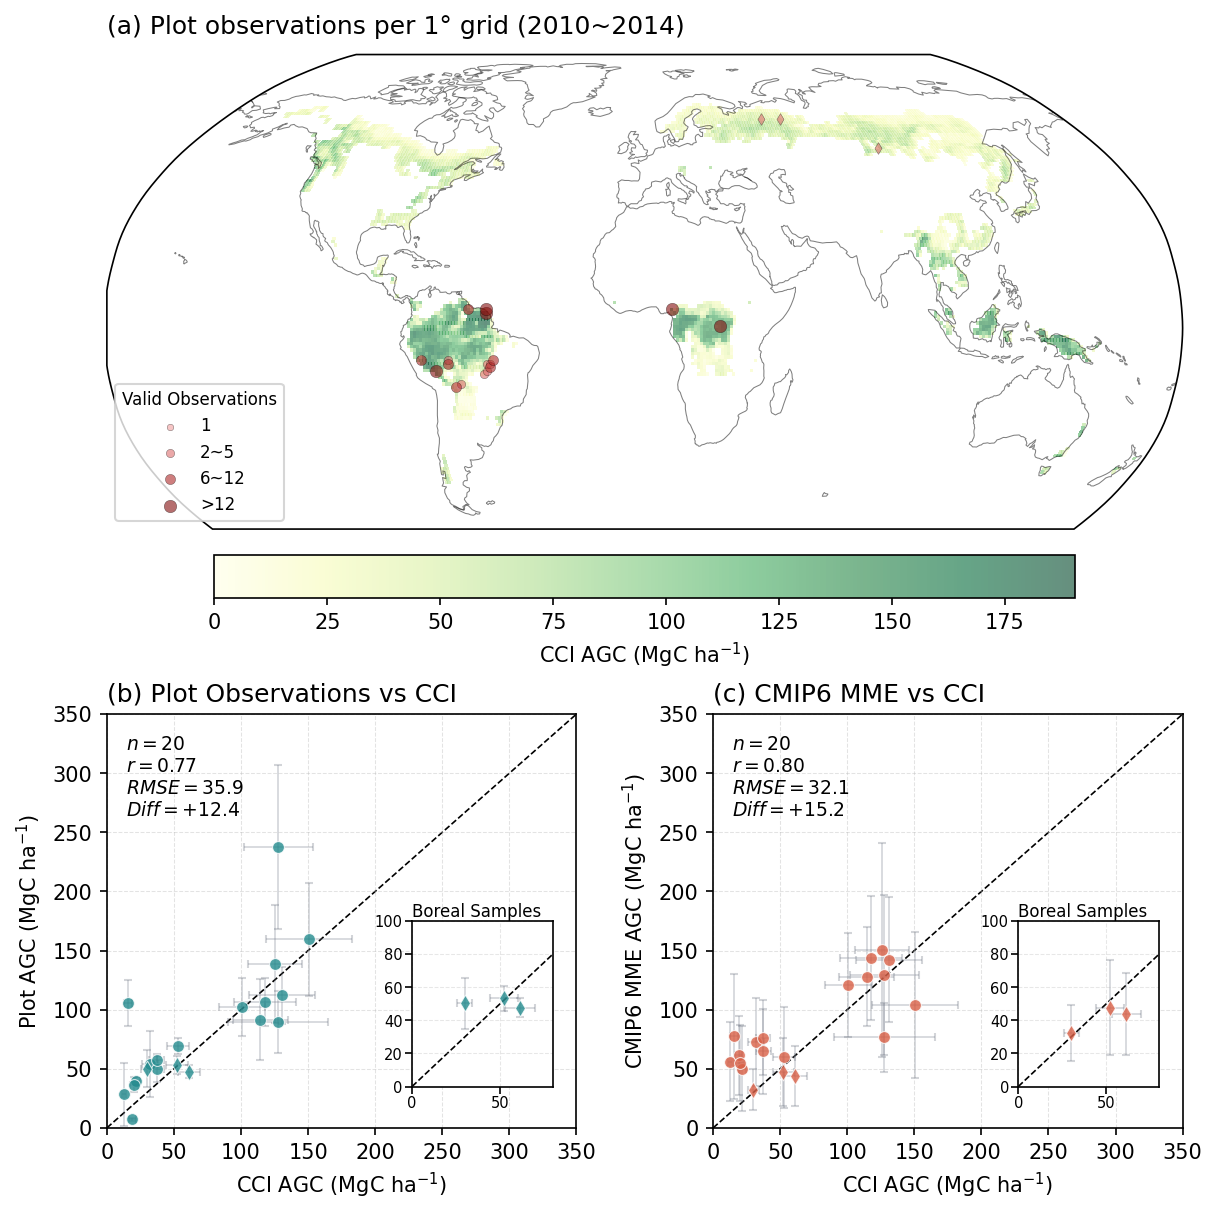

In [36]:
### ----- Figure 2. Comparison at the matched plot grids ----- ###
# Horizontal error bars are CCI standard errors. Vertical error bars are plot-observation
# standard deviations in panel (b) and CMIP6 inter-model standard deviations in panel (c).

def add_points(ax:plt.Axes, x, y, xerr, yerr, color, boreal, size=32):
    ax.errorbar(x, y, xerr=xerr, fmt="none", ecolor="#6b7280",
                elinewidth=0.8, capsize=2, alpha=0.3, zorder=1)
    has_yerr = np.isfinite(yerr)
    ax.errorbar(x[has_yerr], y[has_yerr], yerr=yerr[has_yerr], fmt="none",
                ecolor="#6b7280", elinewidth=0.8, capsize=2, alpha=0.3, zorder=1)
    ax.scatter(x[~boreal], y[~boreal], s=size, marker="o", color=color,
               edgecolor="white", linewidth=0.5, alpha=0.8, zorder=2)
    ax.scatter(x[boreal], y[boreal], s=size, marker="d", color=color,
               edgecolor="white", linewidth=0.5, alpha=0.8, zorder=3)

def add_comparison(ax:plt.Axes, x, y, xerr, yerr, color, boreal, title:str, ylabel:str):
    # Separate horizontal and vertical errors so NaN plot SDs do not hide points.
    add_points(ax, x, y, xerr, yerr, color, boreal)

    valid = np.isfinite(x) & np.isfinite(y)
    r = np.corrcoef(x[valid], y[valid])[0, 1]
    rmse = np.sqrt(np.mean((y[valid] - x[valid]) ** 2))
    diff = np.mean(y[valid] - x[valid])
    ax.text(0.04, 0.95, f"$n = {valid.sum()}$\n$r = {r:.2f}$\n$RMSE = {rmse:.1f}$\n$Diff = {diff:+.1f}$",
            transform=ax.transAxes, va="top", fontsize=9)
    ax.set_title(title, loc="left")
    ax.set_xlabel("CCI AGC (MgC ha$^{-1}$)")
    ax.set_ylabel(str(ylabel))
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.35)

def add_boreal_inset(ax:plt.Axes, x, y, xerr, yerr, color, boreal, xlim, ylim):
    inset = ax.inset_axes([0.65, 0.1, 0.3, 0.4])
    only_boreal = np.ones(boreal.sum(), dtype=bool)
    add_points(
        inset, x[boreal], y[boreal], xerr[boreal], yerr[boreal],
        color, only_boreal, size=32,
    )
    line_min, line_max = max(xlim[0], ylim[0]), min(xlim[1], ylim[1])
    inset.plot([line_min, line_max], [line_min, line_max], color="black",
               linestyle="--", linewidth=0.8, zorder=0)
    inset.set_xlim(*xlim)
    inset.set_ylim(*ylim)
    inset.set_title("Boreal Samples", loc="left", fontsize=8, pad=2)
    inset.tick_params(labelsize=7, pad=1)
    inset.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
    return inset

x = matched["cci_agc"].to_numpy()
xerr = matched["cci_se"].to_numpy()
plot_y = matched["agc_mean"].to_numpy()
plot_yerr = matched["agc_std"].to_numpy()
mme_y = matched["cmip_mme"].to_numpy()
mme_yerr = matched["cmip_sd"].to_numpy()
boreal_mask = matched["is_boreal"].to_numpy()

# trefrac correction
treefrac = matched["treefrac"].to_numpy()
plot_y, plot_yerr = plot_y*treefrac, plot_yerr*treefrac

axis_max = 350  # x-lim, y-lim

fig = plt.figure(figsize=(8, 8), dpi=150, constrained_layout=True)
gs = fig.add_gridspec(2, 2, height_ratios=[1.2, 1.0])

# Add fig. 1
map_ax = fig.add_subplot(gs[0, :], projection=ccrs.Robinson())
add_distribution_map(map_ax)

# Add fig. 2
axes = [
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
]
add_comparison(axes[0], x, plot_y, xerr, plot_yerr, "#238b8e", boreal_mask,
    title="(b) Plot Observations vs CCI", ylabel="Plot AGC (MgC ha$^{-1}$)")
add_comparison(axes[1], x, mme_y, xerr, mme_yerr, "#d95f45", boreal_mask,
    title="(c) CMIP6 MME vs CCI", ylabel="CMIP6 MME AGC (MgC ha$^{-1}$)")
for ax in axes:
    ax.plot([0, axis_max], [0, axis_max], color="black",
            linestyle="--", linewidth=0.8, zorder=0)
    ax.set_xlim(0, axis_max)
    ax.set_ylim(0, axis_max)

# Fixed limits encompass the three Boreal points and their uncertainty ranges.
add_boreal_inset(
    axes[0], x, plot_y, xerr, plot_yerr, "#238b8e",
    boreal_mask, xlim=(0, 80), ylim=(0, 100),
)
add_boreal_inset(
    axes[1], x, mme_y, xerr, mme_yerr, "#d95f45",
    boreal_mask, xlim=(0, 80), ylim=(0, 100),
)

plt.show(fig)
plt.close(fig)


**Observed and Simulated AGC–NPP Curves**

MME NPP models: 27/30
Valid pixels: MODIS/CCI=3518, CMIP6 MME=3518


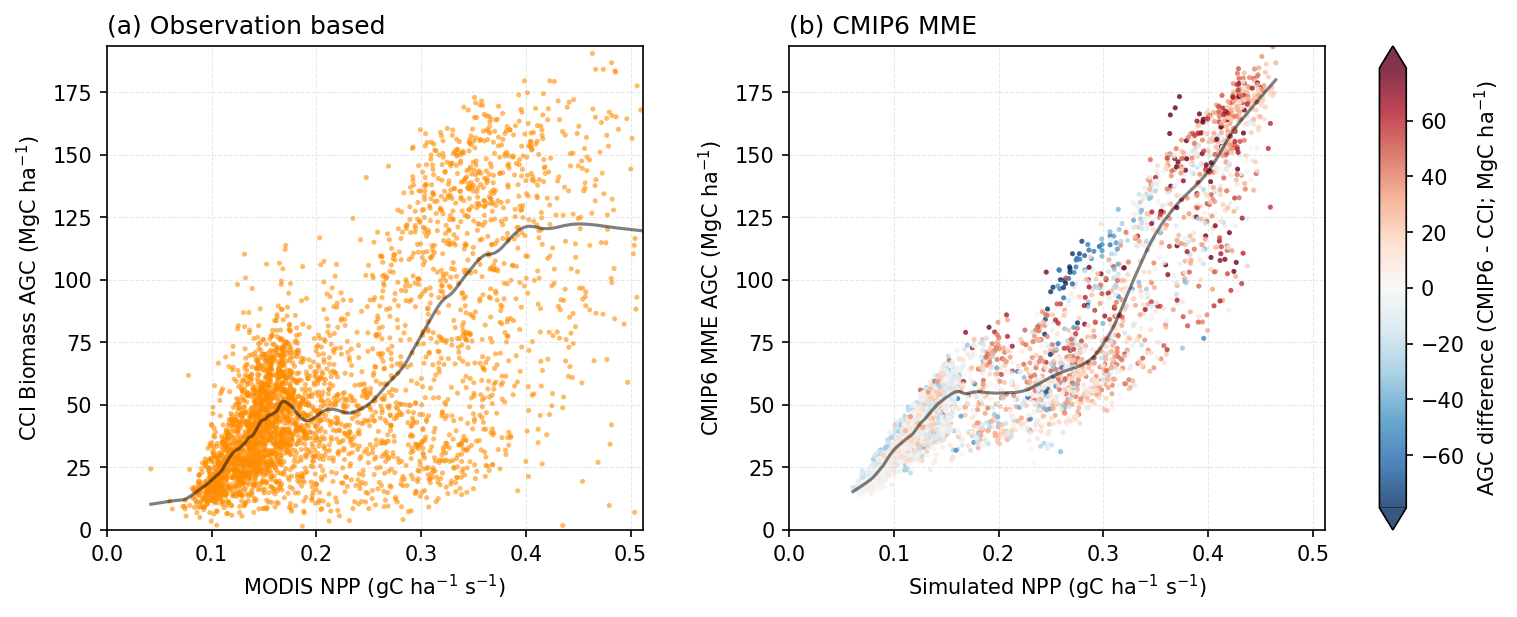

In [37]:
### ----- Figure 3. Observed and simulated AGC-NPP relationships ----- ###
import rasterio
from statsmodels.nonparametric.smoothers_lowess import lowess

# The GeoTIFF is north-to-south and -180~180; flipImage converts it to
# the south-to-north, 0~360 grid used by the CMIP6 arrays.
with rasterio.open(DATA_DIR / "MOD17_NPP_2010-2014_1deg.tif") as src:
    modis_npp = src.read(1, masked=True).filled(np.nan).astype(float)
modis_npp = flipImage(modis_npp)
assert modis_npp.shape == cci_agc.shape
# Mg C ha^-1 yr^-1 -> g C ha^-1 s^-1, consistent with CMIP6 NPP.
factor = 1e6 / (365 * 24 * 60 * 60)
modis_npp *= factor
modis_npp[(modis_npp <= 0) | ~np.isfinite(modis_npp)] = np.nan

# Match the forest/valid-observation mask used by `_04R_2.ipynb`.
with rasterio.open(DATA_DIR / "Koppen_2010.tif") as src:
    koppen_npp = flipImage(src.read(1).astype(np.float32))
forest_npp_mask = np.isfinite(treemask) & (treemask > 0) & (koppen_npp > 0) & (cci_agc > 0)
modis_npp[~forest_npp_mask] = np.nan

# MME NPP: use the same available-model selection, positive-flux filtering,
# unit conversion and pixel-wise ensemble averaging as `_04R_2.ipynb`.
cmip_sup_npp = load(DATA_DIR / "CMIP6_sup.joblib")
simulated_npp_arrays = []
simulated_npp_models = []
for name in model_names:
    npp = cmip_sup_npp.get(name, {}).get("NPP")
    if npp is None: continue
    npp = np.asarray(npp, dtype=np.float32).copy()
    assert npp.shape == cci_agc.shape
    npp[npp <= 0] = np.nan
    npp[~forest_npp_mask] = np.nan
    simulated_npp_arrays.append(npp * 1000.0)  # kgC -> gC
    simulated_npp_models.append(name)
if not simulated_npp_arrays:
    raise ValueError("No CMIP6 models have NPP data for the MME comparison.")
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    simulated_npp_mme = np.nanmean(np.stack(simulated_npp_arrays), axis=0)
simulated_agc_mme = cmip_mme
agc_difference_mme = simulated_agc_mme - cci_agc

observed_valid = forest_npp_mask & np.isfinite(modis_npp) & np.isfinite(cci_agc)
simulated_valid = (forest_npp_mask & np.isfinite(simulated_npp_mme)
                   & np.isfinite(simulated_agc_mme) & np.isfinite(agc_difference_mme))
x_observed, y_observed = modis_npp[observed_valid], cci_agc[observed_valid]
x_simulated, y_simulated = simulated_npp_mme[simulated_valid], simulated_agc_mme[simulated_valid]
if min(x_observed.size, x_simulated.size) <= 10:
    raise ValueError("Too few valid pixels for the observed/simulated NPP comparison.")
print(f"MME NPP models: {len(simulated_npp_models)}/{len(model_names)}")
print(f"Valid pixels: MODIS/CCI={x_observed.size}, CMIP6 MME={x_simulated.size}")

# Equal-size panels with exactly shared x/y limits and ticks.
fig = plt.figure(figsize=(10, 4), dpi=150, constrained_layout=True)
gs = fig.add_gridspec(1, 3, width_ratios=[1.0, 1.0, 0.05], wspace=0.1)
ax_observed = fig.add_subplot(gs[0, 0])
ax_simulated = fig.add_subplot(gs[0, 1], sharex=ax_observed, sharey=ax_observed)
cax = fig.add_subplot(gs[0, 2])

ax_observed.scatter(x_observed, y_observed, color="darkorange", s=6,
                    alpha=0.6, edgecolors="none")
color_lim = float(np.percentile(np.abs(agc_difference_mme[simulated_valid]), 98)) + 5
simulated_scatter = ax_simulated.scatter(
    x_simulated, y_simulated, c=agc_difference_mme[simulated_valid],
    s=6, alpha=0.8, edgecolors="none", cmap="RdBu_r", vmin=-color_lim, vmax=color_lim,
)
for ax, x_vals, y_vals in [
    (ax_observed, x_observed, y_observed),
    (ax_simulated, x_simulated, y_simulated),
]:
    trend = lowess(y_vals, x_vals, frac=0.1, it=1, return_sorted=True)
    ax.plot(trend[:, 0], trend[:, 1], color="black", linewidth=1.5, alpha=0.5)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)

# Cover the percentile ranges of both datasets with one common axis range.
x_bounds = np.array([np.nanpercentile(x_observed, [2, 98]),
                     np.nanpercentile(x_simulated, [2, 98])])
y_bounds = np.array([np.nanpercentile(y_observed, [1, 99]),
                     np.nanpercentile(y_simulated, [1, 99])])
x_lower, x_upper = x_bounds[:, 0].min(), x_bounds[:, 1].max()
y_lower, y_upper = y_bounds[:, 0].min(), y_bounds[:, 1].max()
x_pad, y_pad = 0.1 * (x_upper-x_lower), 0.1 * (y_upper-y_lower)
ax_observed.set_xlim(0, x_upper + x_pad)
ax_observed.set_ylim(0, y_upper + y_pad)

ax_observed.set_title("(a) Observation based", loc="left")
ax_simulated.set_title("(b) CMIP6 MME", loc="left")
ax_observed.set_xlabel("MODIS NPP (gC ha$^{-1}$ s$^{-1}$)")
ax_simulated.set_xlabel("Simulated NPP (gC ha$^{-1}$ s$^{-1}$)")
ax_observed.set_ylabel("CCI Biomass AGC (MgC ha$^{-1}$)")
ax_simulated.set_ylabel("CMIP6 MME AGC (MgC ha$^{-1}$)")
cbar = fig.colorbar(simulated_scatter, cax=cax, extend="both")
cbar.set_label("AGC difference (CMIP6 - CCI; MgC ha$^{-1}$)")

plt.show(fig)
plt.close(fig)
